[1] "Dimensiones totales de la base:"
[1] 14350   327
[1] "Tamaño de la muestra filtrada (Mujeres 18-64 años):"
[1] 6077
[1] "Tamaño de la muestra final depurada: 6042"


Importance of components:
                          PC1    PC2    PC3    PC4
Standard deviation     1.3137 1.0987 0.7885 0.6673
Proportion of Variance 0.4314 0.3018 0.1555 0.1113
Cumulative Proportion  0.4314 0.7332 0.8887 1.0000

,PC1,PC2,PC3,PC4
EDAD_SEL,0.3591739,-0.63990868,0.6627876,0.14907596
TCS_GRUPO_DOMESTICO,-0.1920328,-0.75962440,-0.6199664,-0.04166394
TCS_GRUPO_CUIDADO,-0.6365593,-0.11496283,0.3823750,-0.65982204
CANT_PERSONASHASTA13,-0.6549120,-0.01646791,0.1736195,0.73530630


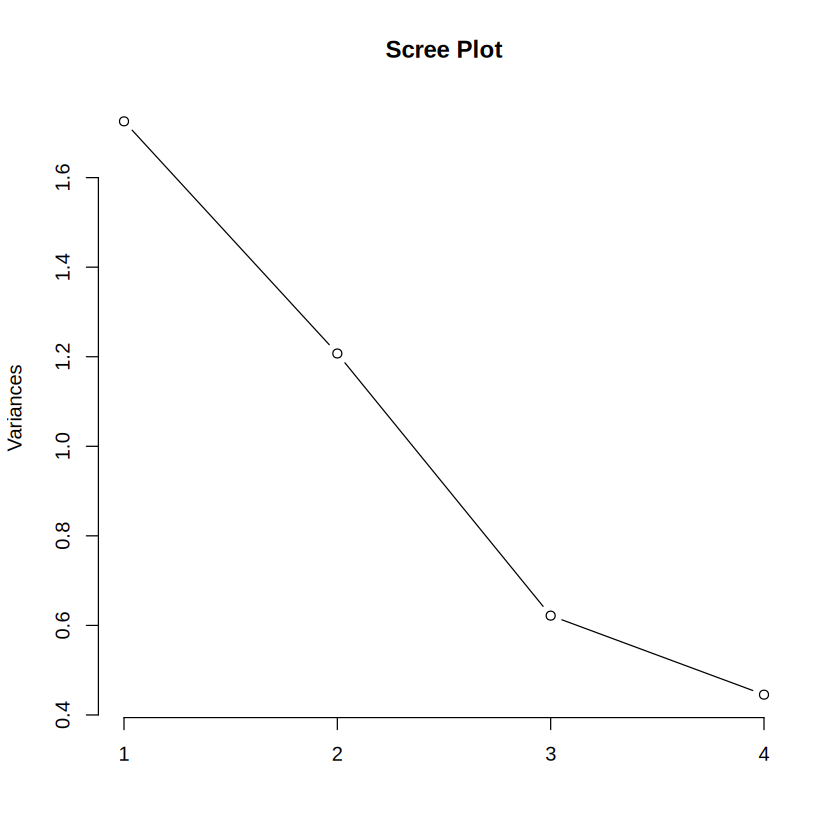

,PC1,PC2,PC3,PC4
EDAD_SEL,0.3591739,-0.63990868,0.6627876,0.14907596
TCS_GRUPO_DOMESTICO,-0.1920328,-0.75962440,-0.6199664,-0.04166394
TCS_GRUPO_CUIDADO,-0.6365593,-0.11496283,0.3823750,-0.65982204
CANT_PERSONASHASTA13,-0.6549120,-0.01646791,0.1736195,0.73530630


educacion,n,PC1,PC2
<chr>,<int>,<dbl>,<dbl>
1. Hasta sec. incompleto,1661,-0.13,-0.37
2. Secundario completo,1678,-0.14,-0.05
3. Terciario/univ. incompleto,1192,0.05,0.63
4. Terciario/univ. completo,1511,0.27,-0.03


servicio,n,PC1,PC2
<chr>,<int>,<dbl>,<dbl>
Con servicio,345,0.26,0.12
Sin servicio,5697,-0.02,-0.01


[1] 5969

Importance of components:
                          PC1    PC2    PC3    PC4
Standard deviation     1.3151 1.0970 0.7891 0.6666
Proportion of Variance 0.4324 0.3009 0.1557 0.1111
Cumulative Proportion  0.4324 0.7333 0.8889 1.0000

,PC1,PC2,PC3,PC4
EDAD_SEL,0.35,-0.65,0.66,0.14
TCS_GRUPO_DOMESTICO,-0.21,-0.75,-0.62,-0.04
TCS_GRUPO_CUIDADO,-0.64,-0.10,0.38,-0.66
CANT_PERSONASHASTA13,-0.65,-0.01,0.18,0.73


,EDAD_SEL,TCS_GRUPO_DOMESTICO,TCS_GRUPO_CUIDADO,CANT_PERSONASHASTA13
EDAD_SEL,1.00,0.21,-0.19,-0.27
TCS_GRUPO_DOMESTICO,0.21,1.00,0.18,0.15
TCS_GRUPO_CUIDADO,-0.19,0.18,1.00,0.55
CANT_PERSONASHASTA13,-0.27,0.15,0.55,1.00


[1] 1.73 1.21 0.62 0.45

[1] "Sin EDAD_SEL"
                           PC1     PC2
Proportion of Variance 0.54477 0.30451
Cumulative Proportion  0.54477 0.84928
[1] "Sin TCS_GRUPO_DOMESTICO"
                           PC1     PC2
Proportion of Variance 0.56717 0.28420
Cumulative Proportion  0.56717 0.85137
[1] "Sin TCS_GRUPO_CUIDADO"
                           PC1     PC2
Proportion of Variance 0.42766 0.38119
Cumulative Proportion  0.42766 0.80885
[1] "Sin CANT_PERSONASHASTA13"
                          PC1     PC2
Proportion of Variance 0.4036 0.39263
Cumulative Proportion  0.4036 0.79624


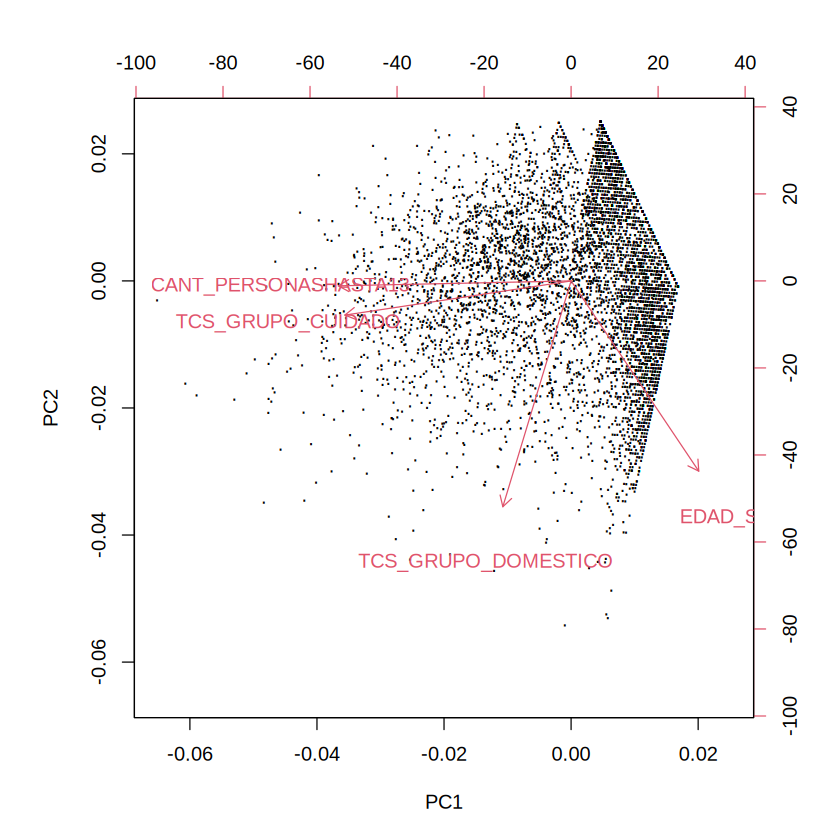

In [4]:
#Análisis de Componentes Principales (PCA)
#Objetivo: resumir 4 variables numéricas (edad, trabajo doméstico, cuidado y niños de 0 a 13) en pocos ejes para ver cómo se organiza el trabajo no remunerado de las mujeres.

# cargado de base de datos
# sep = "|" porque los datos están separados por barras
datos <- read.delim("enut2021_base.txt", sep = "|", header = TRUE, dec = ".")

# Dimensiones iniciales de toda la base
#Muestra cuántas filas y columnas tiene la base completa (14.350 personas y 327 variables).
print("Dimensiones totales de la base:")
print(dim(datos))

# Filtro de la muestra del estudio:
# Mujeres (SEXO_SEL == 1) con edad entre 18 y 64 años (EDAD_SEL)
datos_muestra <- subset(datos, SEXO_SEL == 1 & EDAD_SEL >= 18 & EDAD_SEL <= 64)

# Tamaño de muestra depurada (debe rondar los 6.077 casos)
# Chequea cuántas mujeres quedaron con ese primer filtro (6.077)
print("Tamaño de la muestra filtrada (Mujeres 18-64 años):")
print(nrow(datos_muestra))

# Valores faltantes (exclusión de Ns/nc y educación especial)
# Repite el filtro y además saca los casos con "no sabe/no contesta" y educación especial (códigos 8, 9, 99).
# También saca los "no sabe" en servicio doméstico pago.
datos_muestra <- subset(
  datos,
  SEXO_SEL == 1 &
  EDAD_SEL >= 18 &
  EDAD_SEL <= 64 &
  !(NIVEL_EDUCATIVO_SEL %in% c(8, 9, 99)) &
  !(T_DOMESTICO_PAGO %in% c(9, 99))
)

# Tamaño final de la muestra depurada
print(paste("Tamaño de la muestra final depurada:", nrow(datos_muestra)))

# Carga el paquete tidyverse, que trae las funciones select(), mutate(), group_by(), etc.
library(tidyverse)

# SELECCIÓN DE VARIABLES PARA EL PCA
# Se queda con las 4 variables numéricas. No incluimos WPER porque es el ponderador de la encuesta y no mide nada de las mujeres.
# drop_na() borra filas con datos faltantes (en este caso no borra ninguna).
base_pca <- datos_muestra %>%
  select(
    EDAD_SEL,             # Edad en años cumplidos (discreta)
    TCS_GRUPO_DOMESTICO,  # Minutos diarios en trabajo doméstico no pago - HS_DOMESTICO (continua)
    TCS_GRUPO_CUIDADO,    # Minutos diarios en cuidado directo - HS_CUIDADO (continua)
    CANT_PERSONASHASTA13, # Cantidad de niños de 0 a 13 años en el hogar (discreta)
  ) %>%
  drop_na()

# PCA
# Corre el PCA. center = TRUE resta la media y scale. = TRUE estandariza las variables,
# para que los minutos no pesen más que los años o los niños solo por tener números más grandes.
# (Recordar que scale = TRUE es clave para que todas tengan la misma varianza)
pca_resultado <- prcomp(base_pca, center = TRUE, scale. = TRUE)

# VeMOS el resumen de cuánta varianza explica cada componente
summary(pca_resultado)

# Gráfico de sedimentación (Scree plot) para ver los autovalores
# Dibuja los autovalores de cada componente. Sirve para ver dónde está el "codo", o sea,
# dónde la curva deja de caer fuerte, y decidir cuántos componentes quedarnos.
screeplot(pca_resultado, type = "lines", main = "Scree Plot")

# Ver las cargas (los loadings) para interpretar los ejes
# Muestra cuánto pesa cada variable en cada componente. Sirve para ponerle nombre a los ejes.
pca_resultado$rotation

# Biplot básico para ver las relaciones
# Grafica juntas a las mujeres (puntos) y a las variables (flechas) en PC1 y PC2.
# xlabs = "." reemplaza el número de cada mujer por un punto, para que se pueda leer.
biplot(pca_resultado, xlabs = rep(".", nrow(base_pca)))

# Guardar las dos primeras componentes en la base de datos para seguir analizando
# Guarda en la base el puntaje de cada mujer en PC1 y PC2, para poder compararlos por grupos después.
datos_muestra$PC1 <- pca_resultado$x[, 1]
datos_muestra$PC2 <- pca_resultado$x[, 2]

pca_resultado$rotation

# Puntajes por nivel educativo y por servicio doméstico pago
# Crea dos variables nuevas: el nivel educativo en 4 categorías y si el hogar tiene servicio doméstico pago.
datos_muestra <- datos_muestra %>%
  mutate(
    educacion = case_when(
      NIVEL_EDUCATIVO_SEL %in% 1:4 ~ "1. Hasta sec. incompleto",
      NIVEL_EDUCATIVO_SEL == 5     ~ "2. Secundario completo",
      NIVEL_EDUCATIVO_SEL == 6     ~ "3. Terciario/univ. incompleto",
      NIVEL_EDUCATIVO_SEL == 7     ~ "4. Terciario/univ. completo"),
    servicio = if_else(T_DOMESTICO_PAGO == 1, "Con servicio", "Sin servicio")
  )

# Calcula el puntaje promedio en PC1 y PC2 para cada nivel educativo.
datos_muestra %>% group_by(educacion) %>%
  summarise(n = n(), PC1 = round(mean(PC1), 2), PC2 = round(mean(PC2), 2))

# Lo mismo, pero según si el hogar tiene servicio doméstico pago o no.
datos_muestra %>% group_by(servicio) %>%
  summarise(n = n(), PC1 = round(mean(PC1), 2), PC2 = round(mean(PC2), 2))

# Robustez: PCA sin los 73 outliers (más de 660 min = 11 hs de trabajo doméstico)
# Saca a las 73 mujeres con más de 660 minutos (11 hs) de trabajo doméstico y repite el PCA.
# Sirve para ver si esos casos extremos cambian los resultados.
base_sin_out <- base_pca %>% filter(TCS_GRUPO_DOMESTICO <= 660)
nrow(base_sin_out)   # debe dar 5969
pca_sin_out <- prcomp(base_sin_out, center = TRUE, scale. = TRUE)
summary(pca_sin_out)
round(pca_sin_out$rotation, 2)

# Correlaciones entre las variables (el PCA resume variables relacionadas)
# El PCA sirve cuando las variables se relacionan, porque ahí hay algo que resumir.
round(cor(base_pca), 2)

# Autovalores (criterio de Kaiser: mayor a 1)
# Muestra el autovalor de cada componente. Criterio de Kaiser: nos quedamos con los que superan 1.
round(pca_resultado$sdev^2, 2)

# Sensibilidad: repetir el PCA sacando una variable por vez
# Repite el PCA sacando una variable por vez y muestra el % de varianza de PC1 y PC2.
# Sirve para ver cuánto depende el resultado de cada variable.
for (v in names(base_pca)) {
  pca_prueba <- prcomp(base_pca[, names(base_pca) != v], center = TRUE, scale. = TRUE)
  print(paste("Sin", v))
  print(summary(pca_prueba)$importance[2:3, 1:2])   # % de varianza y acumulado de PC1 y PC2
}


In [5]:
# ---- E. PCA (notebook 04): la prueba con WPER que cita el texto --------------
pca_con_wper <- prcomp(cbind(base_pca, WPER = datos_muestra$WPER),
                       center = TRUE, scale. = TRUE)
cat("\nCargas del PCA incluyendo WPER:\n")
print(round(pca_con_wper$rotation, 2))   # un componente carga casi solo WPER (~0,99)
cat("Autovalores:", round(pca_con_wper$sdev^2, 2), "\n")  # uno vale ~1,00


Cargas del PCA incluyendo WPER:
                       PC1   PC2   PC3   PC4   PC5
EDAD_SEL              0.36 -0.64  0.03  0.66 -0.15
TCS_GRUPO_DOMESTICO  -0.19 -0.76 -0.12 -0.61  0.04
TCS_GRUPO_CUIDADO    -0.64 -0.12  0.05  0.38  0.66
CANT_PERSONASHASTA13 -0.65 -0.02  0.04  0.17 -0.74
WPER                 -0.03  0.06 -0.99  0.12 -0.01
Autovalores: 1.73 1.21 1 0.62 0.45 


## Análisis de componentes principales (PCA)

**Objetivo:** describir cómo se organizan el trabajo doméstico, el cuidado, la edad y la presencia de niños de 0 a 13 años en las mujeres de 18 a 64 años (n = 6.042).

**Decisiones metodológicas**
* **Variables (4):** edad, minutos de trabajo doméstico, minutos de cuidado directo y cantidad de niños de 0 a 13. Son las variables numéricas de nuestras 10 variables principales, y el PCA solo admite variables cuantitativas.
* **Excluidas:** WPER (al incluirla aparece un componente que solo la capta, sin interpretación) y las variables categóricas (nivel educativo y servicio pago), que se usan después para comparar puntajes.
* **Estandarización:** necesaria porque las variables tienen unidades distintas.
* **Sin ponderador:** el análisis describe a la muestra, no a la población.
* **Cantidad de componentes:** autovalor mayor a 1 (Kaiser), codo del gráfico de sedimentación y varianza acumulada. Los tres coinciden en 2 componentes (73,3%).

**Resultados**
* **PC1 (43,1%): cuidado infantil.** Cargas: cuidado −0,64, niños −0,65, edad +0,36. Un puntaje bajo corresponde a más niños y más horas de cuidado.
* **PC2 (30,2%): trabajo doméstico y edad.** Cargas: doméstico −0,76, edad −0,64. Un puntaje bajo corresponde a mujeres de más edad con más horas de trabajo doméstico.
* **Por nivel educativo:** PC1 sube de −0,13 (hasta secundario incompleto) a 0,27 (terciario/universitario completo), es decir, menos carga de cuidado infantil. En PC2, terciario/universitario incompleto se ubica en 0,63: es el grupo más joven y con menos trabajo doméstico.
* **Servicio pago:** puntaje más alto en PC1 (0,26 vs −0,02). Pero ese eje incluye la cantidad de niños y la edad, así que refleja en parte el perfil de esas mujeres. La regresión indica que el servicio se asocia con menos trabajo doméstico, no con menos cuidado.
* **Robustez:** sin los 73 outliers los resultados casi no cambian (43,2% y 30,1%). Al sacar una variable por vez, el resultado depende bastante de cada una.

**Limitaciones**
* Con solo 4 variables hay poco que resumir. El cuidado y los niños están correlacionados por construcción (r = 0,55), lo que refuerza PC1.
* Hay muchos ceros y asimetría; el PCA es sensible a eso y a los valores extremos.
* No usa ponderador, y las diferencias entre grupos son descriptivas y no se testearon.
* El PCA describe, no explica: no permite hablar de causas.
